In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("cleaned_data.csv",index_col=0)
df

,ride_id,distance_km,rider_type,weekend,weather,duration_minutes
0,R001,4.2,Member,False,Clear,22.0
1,R002,8.5,Casual,True,Cloudy,45.0
2,R003,3.1,Member,False,Clear,18.0
3,R004,10.2,Casual,True,Rain,55.0
4,R005,6.0,Member,False,Cloudy,30.0
5,R006,12.0,Casual,True,Rain,64.0
6,R007,0.0,Member,False,Clear,20.0
7,R008,7.5,Unknown,True,Cloudy,41.0
8,R009,9.0,Casual,True,Clear,48.0
9,R010,2.5,Member,False,Clear,15.0


calculate the mean and median ride duration with NumPy

In [4]:
duration = df["duration_minutes"].to_numpy()

mean_duration = np.mean(duration)
median_duration = np.median(duration)

print(F"Mean duration: {mean_duration:.2f}minutes")
print(F"Median duration: {median_duration:.2f}minutes")

Mean duration: 32.55minutes
Median duration: 30.00minutes


calculate the correlation between distance and duration

In [5]:
distance = df["distance_km"].to_numpy()

correlation = np.corrcoef(
    distance,
    duration
)[0,1]

print(f"Correlation: {correlation:.3f}")

Correlation: 0.852


create a scatter plot of distance versus duration

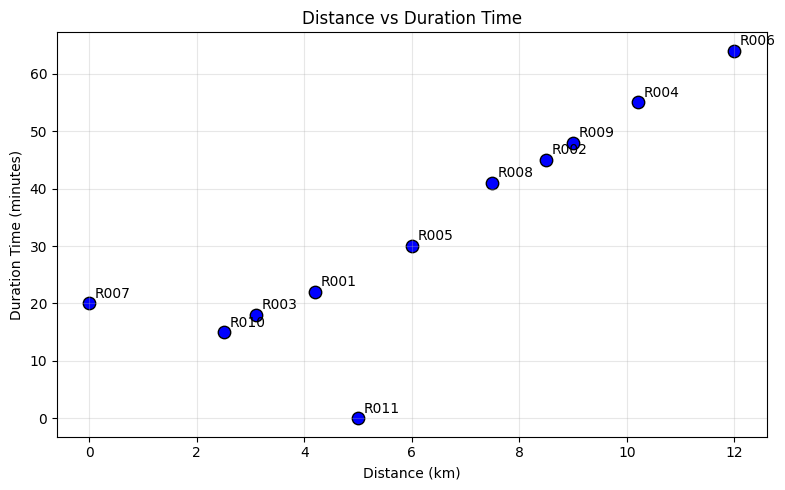

In [6]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["distance_km"],
    df["duration_minutes"],
    color="b",
    s=80,
    edgecolors="black"
)

for _, row in df.iterrows():
    plt.annotate(
        row["ride_id"],
        (
            row["distance_km"],
            row["duration_minutes"]
        ),
        xytext=(4,4),
        textcoords="offset points"
    )

plt.title("Distance vs Duration Time")
plt.xlabel("Distance (km)")
plt.ylabel("Duration Time (minutes)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

create a bar chart comparing average duration for members and casual riders

In [7]:
member_duration = df.loc[
    df["rider_type"] == "Member",
    "duration_minutes"
].to_numpy()

casual_duration = df.loc[
    df["rider_type"] == "Casual",
    "duration_minutes"
].to_numpy()

member_average = np.mean(member_duration)
casual_average = np.mean(casual_duration)

print(f"Member average: {member_average:.2f}")
print(f"Casual average: {casual_average:.2f}")

Member average: 21.00
Casual average: 42.40


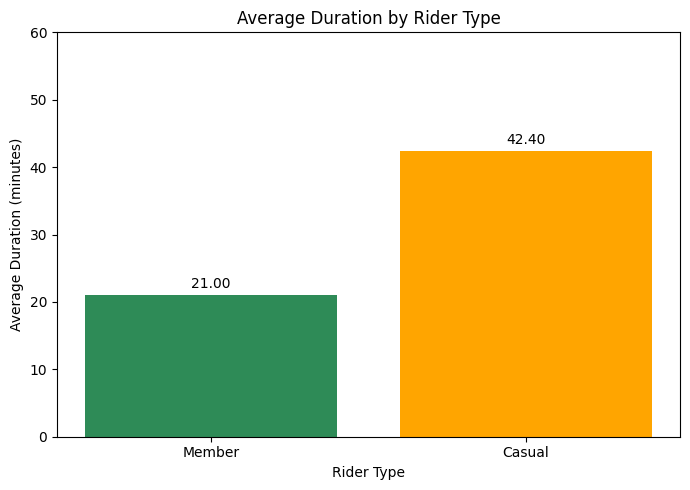

In [8]:
labels = ["Member","Casual"]
averages = [member_average,casual_average]

plt.figure(figsize=(7,5))

bars = plt.bar(
    labels,
    averages,
    color=["seagreen","orange"]
)

plt.title("Average Duration by Rider Type")
plt.xlabel("Rider Type")
plt.ylabel("Average Duration (minutes)")
plt.ylim(0,60)

for bar, value in zip(bars, averages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()